# Rates market maker: managing inventory risk with quote skew

Educational simulation of a bond market maker. A 10-year bond is quoted two-way to probabilistic clients; position, cash, mark-to-market P&L and DV01 are tracked. Three ways of controlling inventory risk are compared on identical simulated markets:

- **A**: fixed spread, no risk control (baseline)
- **A + limit**: fixed spread with a hard DV01 limit
- **B**: quotes skewed by the inventory (alone, and with the same hard limit)

The functions are in `market_maker.py` and are tested in `tests/`. This notebook contains the experiments. The model is deliberately simple; see the README for its limitations.

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market_maker import (bond_price, bond_price_loop, calculation_DV01, position_dv01,
                          simulate_rates, draw_client_uniforms, simulate_market,
                          run_strategy, summarise, describe_summary,
                          evaluate_variants, average_over_simulations)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
os.makedirs("figures", exist_ok=True)

## 1. Parameters

In [2]:
PARAMS = dict(
    # bond
    nominal=100, coupon=0.04, maturity=10,
    # rates: arithmetic random walk, sigma in bp per step
    initial_rate=0.04, sigma_bp=0.15, n_paths=500, n_steps=50,
    # quotes and clients
    half_spread=0.02, flow=0.3, sensitivity=30, trade_size=1_000_000,
)
SEED_PAIRS = [(1, 2), (3, 4), (5, 6), (7, 8), (9, 10)]   # (rates seed, clients seed), 5 independent simulations

## 2. Market data and pricer check

One simulated path with the bond price and DV01 it implies, then a check that the vectorised pricer agrees with a plain loop and how much faster it is.

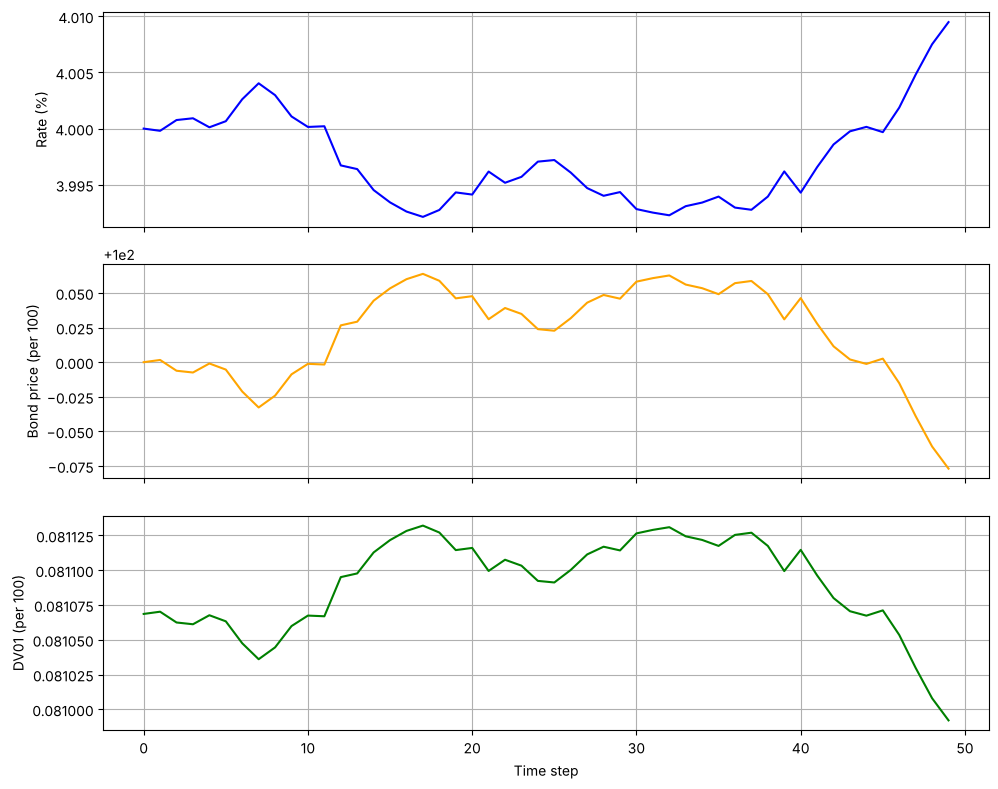

In [3]:
p = PARAMS
rates_1 = simulate_rates(p["initial_rate"], 1, p["n_steps"], p["sigma_bp"], seed=0)
prices_1 = bond_price(rates_1, p["nominal"], p["coupon"], p["maturity"])
dv01_1 = calculation_DV01(rates_1, p["nominal"], p["coupon"], p["maturity"])

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(rates_1[0] * 100, color="blue"); axes[0].set_ylabel("Rate (%)")
axes[1].plot(prices_1[0], color="orange"); axes[1].set_ylabel("Bond price (per 100)")
axes[2].plot(dv01_1[0], color="green"); axes[2].set_ylabel("DV01 (per 100)"); axes[2].set_xlabel("Time step")
for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.show()

In [4]:
rates_matrix = np.random.default_rng(0).uniform(0.01, 0.08, size=(100, 1000))

t0 = time.perf_counter()
fast = bond_price(rates_matrix, 100, 0.04, 10)
t_fast = time.perf_counter() - t0

t0 = time.perf_counter()
slow = np.array([bond_price_loop(r, 100, 0.04, 10) for r in rates_matrix.ravel()]).reshape(rates_matrix.shape)
t_slow = time.perf_counter() - t0

print(f"same result: {np.allclose(fast, slow)}  |  vectorised {t_fast * 1e3:.1f} ms, loop {t_slow * 1e3:.0f} ms, "
      f"speed-up ~{t_slow / t_fast:.0f}x")

same result: True  |  vectorised 19.8 ms, loop 375 ms, speed-up ~19x


## 3. Strategy A and the hard DV01 limit

Strategy A quotes a fixed spread around the fair price. Its inventory is a random walk with nothing pulling it back. The hard limit refuses any trade that would push the absolute position DV01 above the limit; trades that reduce risk are always accepted.

In [5]:
market = simulate_market(PARAMS, *SEED_PAIRS[0])
prices, dv01_per_100, u_buy, u_sell = (market[k] for k in ("prices", "dv01_per_100", "u_buy", "u_sell"))

def run(skew=0.0, dv01_limit=None, mkt=market, params=PARAMS):
    res = run_strategy(mkt["prices"], mkt["u_buy"], mkt["u_sell"], params["half_spread"],
                       params["flow"], params["sensitivity"], mkt["dv01_per_100"],
                       trade_size=params["trade_size"], skew=skew, dv01_limit=dv01_limit)
    dv01 = position_dv01(res["position"], mkt["dv01_per_100"])
    return res, dv01, summarise(res, dv01)

dv01_limits = [None, 5000, 3200]
runs_A = {limit: run(dv01_limit=limit) for limit in dv01_limits}
results_A, dv01_position_A, summary_A = runs_A[None]

comparison = pd.DataFrame({f"A, limit {limit}": describe_summary(runs_A[limit][2]) for limit in dv01_limits})
print(comparison.round(2))

                               A, limit None  A, limit 5000  A, limit 3200
mean final P&L                       3214.60        3129.84        2917.73
std of final P&L                     2638.17        2401.72        1738.35
5th percentile of final P&L         -1088.18       -1085.88          -6.61
share of losing paths                   0.08           0.08           0.05
mean of max |DV01|                   3436.42        3209.56        2277.29
95th percentile of max |DV01|        6487.33        4869.36        2436.16
mean of mean |DV01|                  1618.08        1554.86        1159.26


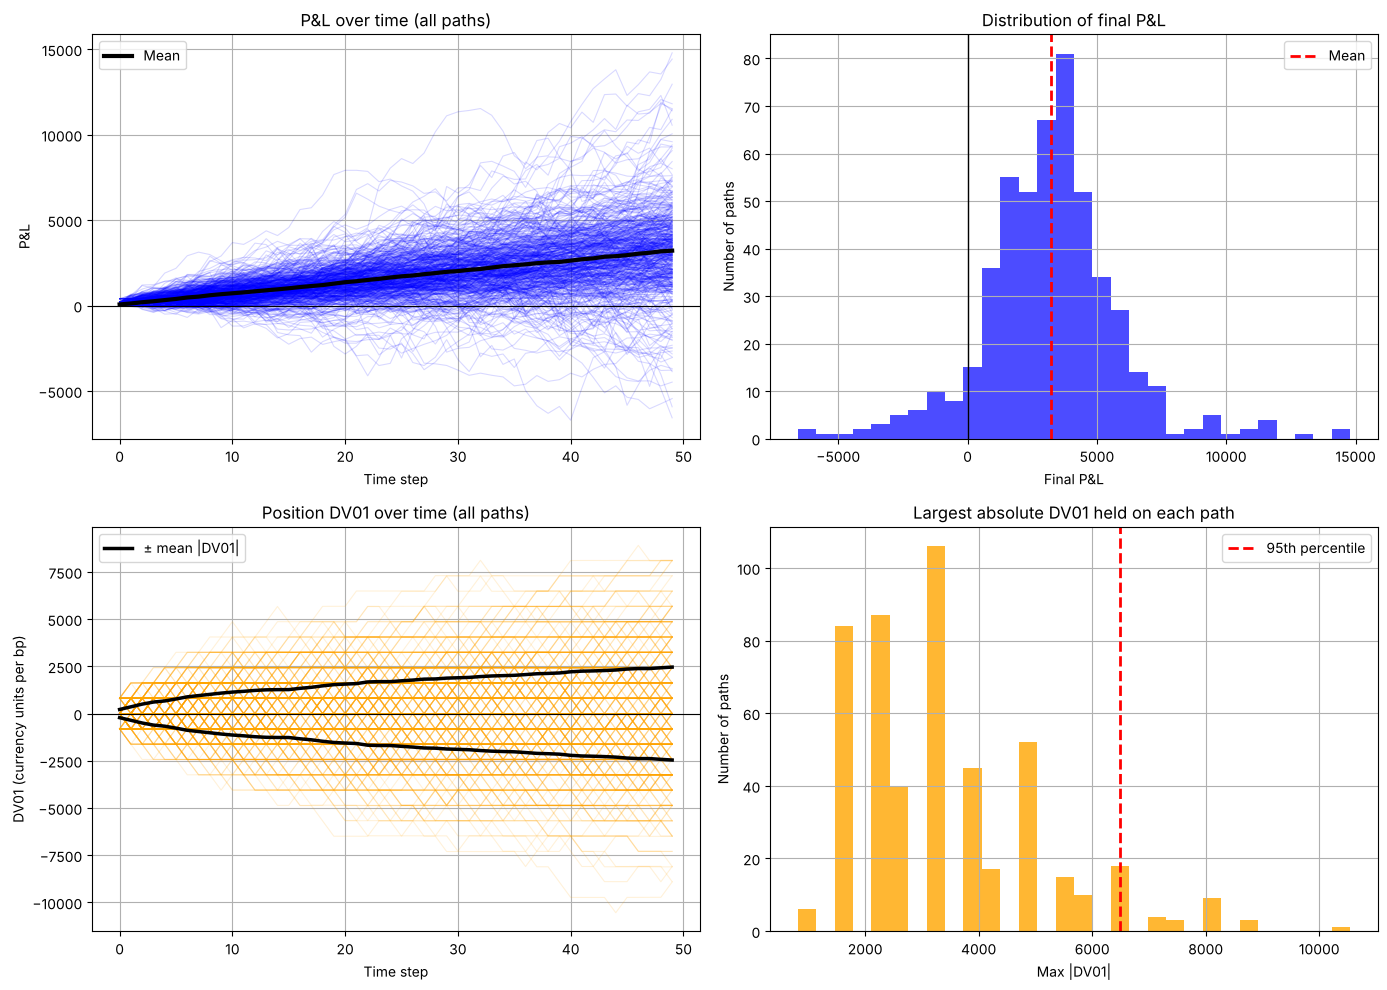

In [6]:
# Strategy A without limit: P&L and risk over 500 paths
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(results_A["pnl"].T, color="blue", alpha=0.15, linewidth=0.8)
axes[0, 0].plot(results_A["pnl"].mean(axis=0), color="black", linewidth=3, zorder=5, label="Mean")
axes[0, 0].axhline(0, color="black", linewidth=0.8)
axes[0, 0].set(title="P&L over time (all paths)", xlabel="Time step", ylabel="P&L")

axes[0, 1].hist(summary_A["final_pnl"], bins=30, color="blue", alpha=0.7)
axes[0, 1].axvline(0, color="black", linewidth=1)
axes[0, 1].axvline(summary_A["final_pnl"].mean(), color="red", linewidth=2, linestyle="--", label="Mean")
axes[0, 1].set(title="Distribution of final P&L", xlabel="Final P&L", ylabel="Number of paths")

mean_abs_dv01 = np.abs(dv01_position_A).mean(axis=0)
axes[1, 0].plot(dv01_position_A.T, color="orange", alpha=0.15, linewidth=0.8)
axes[1, 0].plot(mean_abs_dv01, color="black", linewidth=2.5, zorder=5, label="± mean |DV01|")
axes[1, 0].plot(-mean_abs_dv01, color="black", linewidth=2.5, zorder=5)
axes[1, 0].axhline(0, color="black", linewidth=0.8)
axes[1, 0].set(title="Position DV01 over time (all paths)", xlabel="Time step", ylabel="DV01 (currency units per bp)")

axes[1, 1].hist(summary_A["max_abs_dv01"], bins=30, color="orange", alpha=0.8)
axes[1, 1].axvline(np.percentile(summary_A["max_abs_dv01"], 95), color="red", linewidth=2, linestyle="--", label="95th percentile")
axes[1, 1].set(title="Largest absolute DV01 held on each path", xlabel="Max |DV01|", ylabel="Number of paths")

for ax in axes.ravel():
    ax.grid(True); ax.legend() if ax.get_legend_handles_labels()[0] else None
plt.tight_layout()
plt.savefig("figures/strategy_A_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

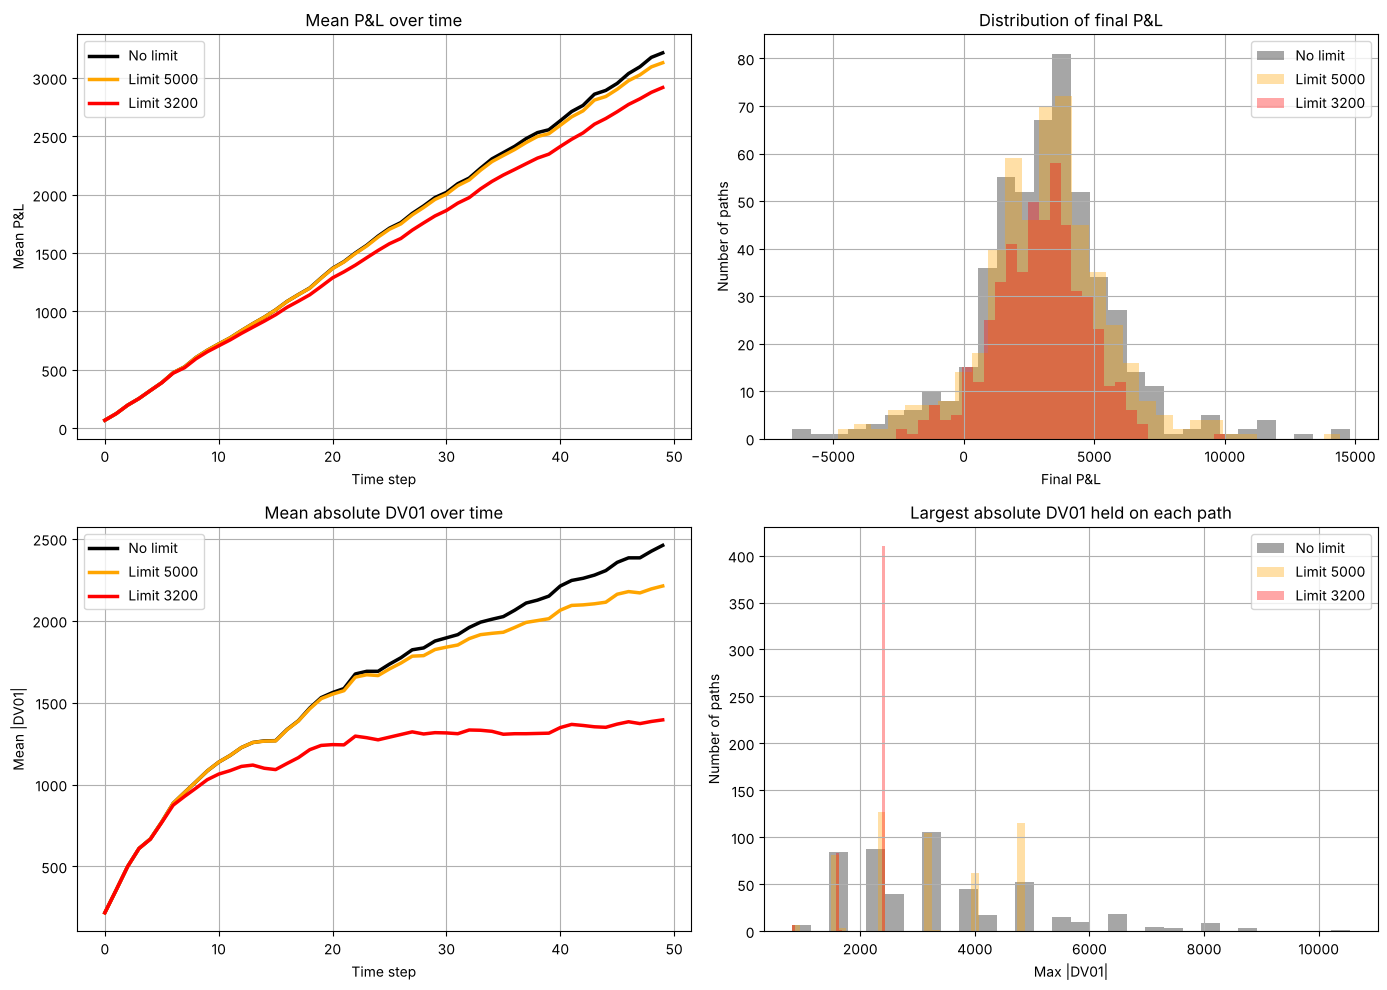

In [7]:
# Effect of the hard limit
colors = {None: "black", 5000: "orange", 3200: "red"}
labels = {limit: "No limit" if limit is None else f"Limit {limit}" for limit in dv01_limits}
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for limit in dv01_limits:
    res, dv01, summ = runs_A[limit]
    axes[0, 0].plot(res["pnl"].mean(axis=0), color=colors[limit], linewidth=2.5, label=labels[limit])
    axes[0, 1].hist(summ["final_pnl"], bins=30, color=colors[limit], alpha=0.35, label=labels[limit])
    axes[1, 0].plot(np.abs(dv01).mean(axis=0), color=colors[limit], linewidth=2.5, label=labels[limit])
    axes[1, 1].hist(summ["max_abs_dv01"], bins=30, color=colors[limit], alpha=0.35, label=labels[limit])

axes[0, 0].set(title="Mean P&L over time", xlabel="Time step", ylabel="Mean P&L")
axes[0, 1].set(title="Distribution of final P&L", xlabel="Final P&L", ylabel="Number of paths")
axes[1, 0].set(title="Mean absolute DV01 over time", xlabel="Time step", ylabel="Mean |DV01|")
axes[1, 1].set(title="Largest absolute DV01 held on each path", xlabel="Max |DV01|", ylabel="Number of paths")
for ax in axes.ravel():
    ax.grid(True); ax.legend()
plt.tight_layout()
plt.show()

## 4. Strategy B: inventory skew

Both quotes are shifted against the position: `shift = skew * position DV01 / 1000`, `bid = fair - half_spread - shift`, `ask = fair + half_spread - shift`. When long, quotes move down, so clients are more likely to buy from us and less likely to sell to us; the spread width is unchanged. The skew is in price points per 1,000 of DV01. Below, the mechanism on a single path (skew 0.01), with strategy A as reference.

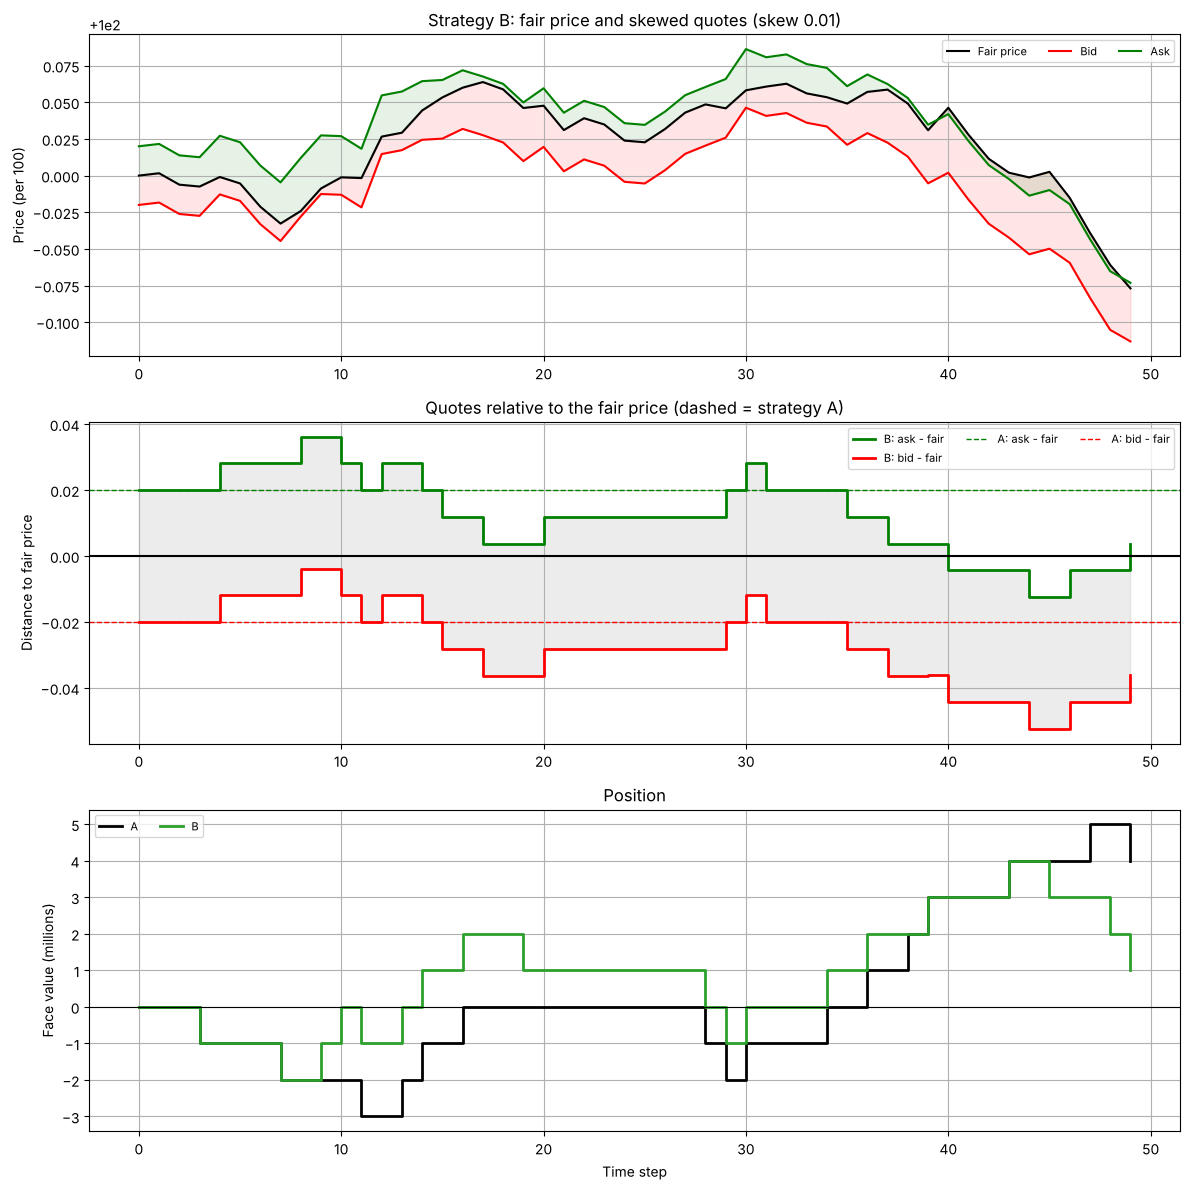

In [8]:
skew_demo = 0.01
u_buy_1, u_sell_1 = draw_client_uniforms(1, p["n_steps"], seed=2)
single = dict(prices=prices_1, u_buy=u_buy_1, u_sell=u_sell_1, dv01_per_100=dv01_1)
res_A1 = run(skew=0.0, mkt=single)[0]
res_B1 = run(skew=skew_demo, mkt=single)[0]
steps = np.arange(p["n_steps"])
bid_gap = res_B1["bid"][0] - prices_1[0]
ask_gap = res_B1["ask"][0] - prices_1[0]

fig, axes = plt.subplots(3, 1, figsize=(12, 12))
axes[0].plot(steps, prices_1[0], color="black", label="Fair price")
axes[0].plot(steps, res_B1["bid"][0], color="red", label="Bid")
axes[0].plot(steps, res_B1["ask"][0], color="green", label="Ask")
axes[0].fill_between(steps, res_B1["bid"][0], prices_1[0], color="red", alpha=0.1)
axes[0].fill_between(steps, prices_1[0], res_B1["ask"][0], color="green", alpha=0.1)
axes[0].set(title=f"Strategy B: fair price and skewed quotes (skew {skew_demo})", ylabel="Price (per 100)")

axes[1].step(steps, ask_gap, where="post", color="green", linewidth=2, label="B: ask - fair")
axes[1].step(steps, bid_gap, where="post", color="red", linewidth=2, label="B: bid - fair")
axes[1].fill_between(steps, bid_gap, ask_gap, step="post", color="grey", alpha=0.15)
axes[1].axhline(p["half_spread"], color="green", linestyle="--", linewidth=1, label="A: ask - fair")
axes[1].axhline(-p["half_spread"], color="red", linestyle="--", linewidth=1, label="A: bid - fair")
axes[1].axhline(0, color="black", linewidth=1.5)
axes[1].set(title="Quotes relative to the fair price (dashed = strategy A)", ylabel="Distance to fair price")

axes[2].step(steps, res_A1["position"][0] / 1e6, where="post", color="black", linewidth=2, label="A")
axes[2].step(steps, res_B1["position"][0] / 1e6, where="post", color="tab:green", linewidth=2, label="B")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set(title="Position", xlabel="Time step", ylabel="Face value (millions)")
for ax in axes:
    ax.grid(True); ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.savefig("figures/skew_mechanism.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Robustness over independent simulations

The same comparison on 5 independent simulations (new rates and new clients each time; within a simulation all strategies see the same data). The first table is the average, the second the standard deviation between simulations, i.e. the noise to compare differences against.

In [9]:
key_variants = {
    "A":                          dict(skew=0.0,   dv01_limit=None),
    "A, limit 3200":              dict(skew=0.0,   dv01_limit=3200),
    "B, skew 0.005 + limit 3200": dict(skew=0.005, dv01_limit=3200),
    "B, skew 0.01 + limit 3200":  dict(skew=0.01,  dv01_limit=3200),
}
robust = evaluate_variants(key_variants, PARAMS, SEED_PAIRS)
table_mean, table_std = average_over_simulations(robust)

print("Average over the 5 simulations:")
print(table_mean.round(1))
print("\nStandard deviation between the 5 simulations:")
print(table_std.round(1))

Average over the 5 simulations:
                            mean P&L  std P&L  5th pct P&L  % losing  mean max DV01  95th pct max DV01  mean DV01
variant                                                                                                          
A                             3236.2   2459.2       -628.4       7.1         3374.3             6485.2     1587.4
A, limit 3200                 2978.3   1685.9         99.9       5.0         2257.1             2436.0     1146.6
B, skew 0.005 + limit 3200    3006.5   1428.6        618.1       2.3         2088.3             2435.5      913.2
B, skew 0.01 + limit 3200     2874.7   1214.5        973.6       1.2         1896.5             2434.6      733.2

Standard deviation between the 5 simulations:
                            mean P&L  std P&L  5th pct P&L  % losing  mean max DV01  95th pct max DV01  mean DV01
variant                                                                                                          
A        

## 6. Skew calibration

Grid of 11 skews with the hard limit fixed at 3,200, averaged over the 5 simulations. Criterion, fixed before looking at the results: **the largest risk reduction that costs at most 5% of the mean P&L of A + limit** (skew 0).

         mean P&L  std P&L  5th pct P&L  mean DV01  mean P&L vs skew 0 (%)  std P&L vs skew 0 (%)
variant                                                                                          
0.0000     2978.3   1685.9         99.9     1146.6                     0.0                    0.0
0.0025     3021.6   1555.9        416.9     1022.6                     1.5                   -7.7
0.0050     3006.5   1428.6        618.1      913.2                     0.9                  -15.3
0.0075     2956.5   1308.7        898.7      815.7                    -0.7                  -22.4
0.0100     2874.7   1214.5        973.6      733.2                    -3.5                  -28.0
0.0125     2787.1   1147.1       1017.4      664.8                    -6.4                  -32.0
0.0150     2690.0   1081.4        992.7      610.1                    -9.7                  -35.9
0.0200     2444.9    983.5        898.4      527.1                   -17.9                  -41.7
0.0250     2177.7   

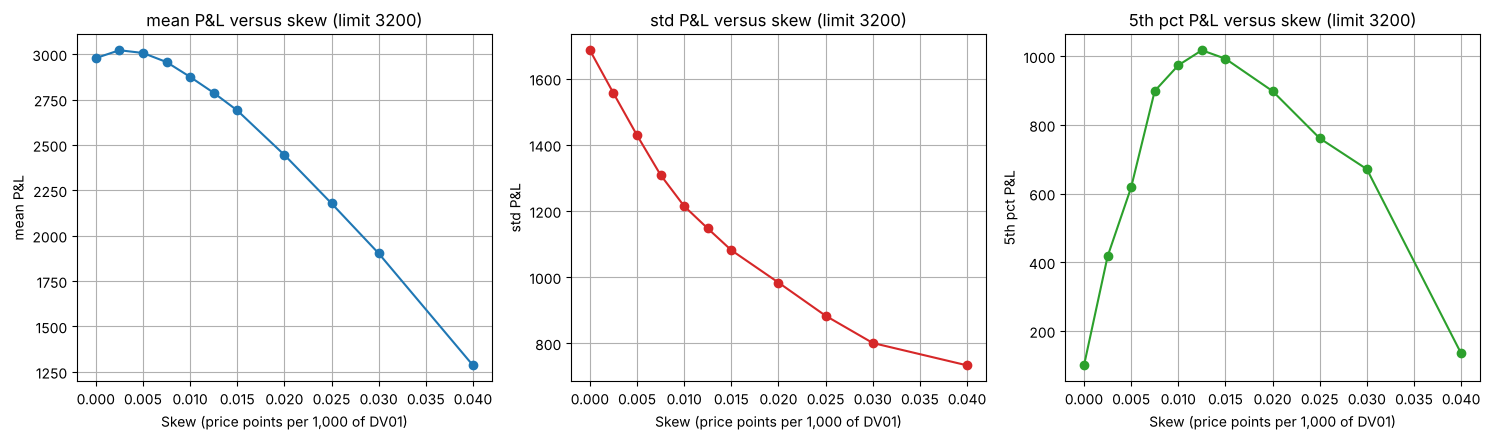

In [10]:
FIXED_LIMIT = 3200
SKEW_GRID = [0.0, 0.0025, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.025, 0.03, 0.04]

grid = evaluate_variants({s: dict(skew=s, dv01_limit=FIXED_LIMIT) for s in SKEW_GRID}, PARAMS, SEED_PAIRS)
curve = average_over_simulations(grid)[0][["mean P&L", "std P&L", "5th pct P&L", "mean DV01"]]
curve["mean P&L vs skew 0 (%)"] = (curve["mean P&L"] / curve.loc[0.0, "mean P&L"] - 1) * 100
curve["std P&L vs skew 0 (%)"] = (curve["std P&L"] / curve.loc[0.0, "std P&L"] - 1) * 100
print(curve.round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, column, color in zip(axes, ["mean P&L", "std P&L", "5th pct P&L"], ["tab:blue", "tab:red", "tab:green"]):
    ax.plot(curve.index, curve[column], marker="o", color=color)
    ax.set(title=f"{column} versus skew (limit {FIXED_LIMIT})", xlabel="Skew (price points per 1,000 of DV01)", ylabel=column)
    ax.grid(True)
plt.tight_layout()
plt.savefig("figures/skew_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

### Out-of-sample check

Choosing and evaluating on the same simulations flatters the result, so the criterion is applied separately to simulations 1-3 and to simulations 4-5.

In [11]:
def apply_criterion(simulations, budget_pct=5.0):
    mean_pnl = grid[grid["simulation"].isin(simulations)].groupby("variant")["mean final P&L"].mean()
    change = (mean_pnl / mean_pnl.loc[0.0] - 1) * 100
    return change[change >= -budget_pct].index.max(), change

for name, sims in {"calibration (sims 1-3)": [0, 1, 2], "test (sims 4-5)": [3, 4]}.items():
    chosen, change = apply_criterion(sims)
    print(f"{name}: chosen skew {chosen} | mean P&L change at 0.01: {change[0.01]:.1f}%, at 0.0125: {change[0.0125]:.1f}%")

calibration (sims 1-3): chosen skew 0.01 | mean P&L change at 0.01: -2.9%, at 0.0125: -5.8%
test (sims 4-5): chosen skew 0.01 | mean P&L change at 0.01: -4.4%, at 0.0125: -7.3%


## 7. Final results

Skew 0.01 (from the calibration) and a hard limit of 3,200 shared by A and B. The table averages the 5 simulations; the figure uses the first one only, so its values differ slightly from the table.

In [12]:
FINAL_SKEW, FINAL_LIMIT = 0.01, 3200
final_variants = {
    "A: fixed spread":      dict(skew=0.0,         dv01_limit=None),
    "A + DV01 limit":       dict(skew=0.0,         dv01_limit=FINAL_LIMIT),
    "B: skew":              dict(skew=FINAL_SKEW,  dv01_limit=None),
    "B: skew + DV01 limit": dict(skew=FINAL_SKEW,  dv01_limit=FINAL_LIMIT),
}

final_table = average_over_simulations(evaluate_variants(final_variants, PARAMS, SEED_PAIRS))[0]
print("Average over 5 independent simulations (500 paths x 50 steps each)")
print(final_table.round(1))

Average over 5 independent simulations (500 paths x 50 steps each)
                      mean P&L  std P&L  5th pct P&L  % losing  mean max DV01  95th pct max DV01  mean DV01
variant                                                                                                    
A: fixed spread         3236.2   2459.2       -628.4       7.1         3374.3             6485.2     1587.4
A + DV01 limit          2978.3   1685.9         99.9       5.0         2257.1             2436.0     1146.6
B: skew                 2920.9   1260.9        983.8       1.2         1969.4             3242.2      747.7
B: skew + DV01 limit    2874.7   1214.5        973.6       1.2         1896.5             2434.6      733.2


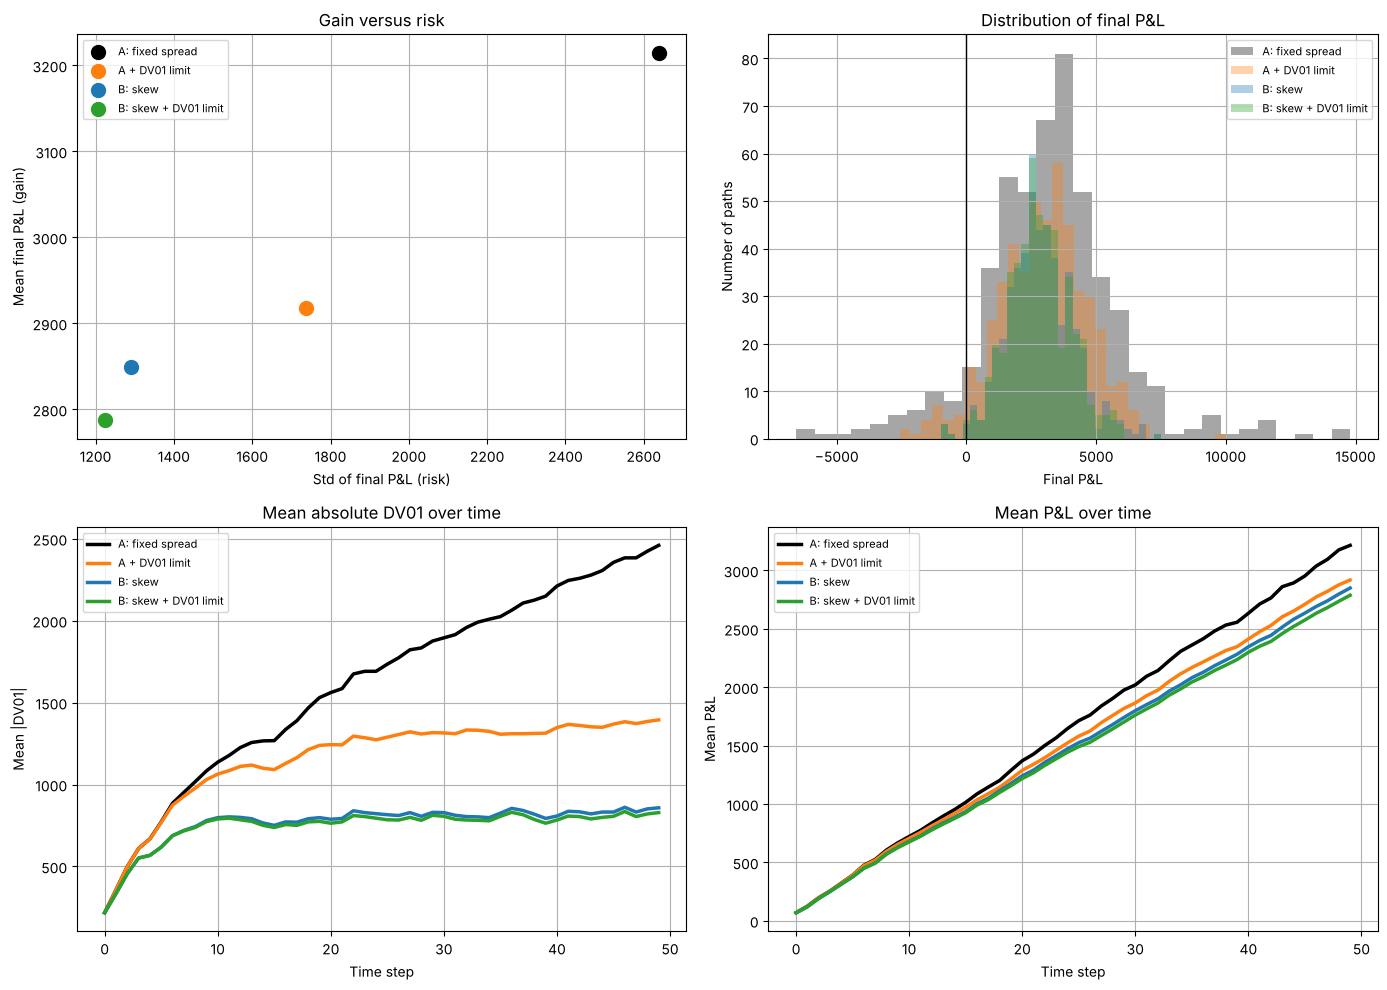

In [13]:
runs_f = {name: run(**kwargs) for name, kwargs in final_variants.items()}
colors_f = {"A: fixed spread": "black", "A + DV01 limit": "tab:orange",
            "B: skew": "tab:blue", "B: skew + DV01 limit": "tab:green"}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for name, (res, dv01, summ) in runs_f.items():
    c = colors_f[name]
    axes[0, 0].scatter(summ["final_pnl"].std(), summ["final_pnl"].mean(), color=c, s=100, label=name, zorder=3)
    axes[0, 1].hist(summ["final_pnl"], bins=30, color=c, alpha=0.35, label=name)
    axes[1, 0].plot(np.abs(dv01).mean(axis=0), color=c, linewidth=2.5, label=name)
    axes[1, 1].plot(res["pnl"].mean(axis=0), color=c, linewidth=2.5, label=name)

axes[0, 0].set(title="Gain versus risk", xlabel="Std of final P&L (risk)", ylabel="Mean final P&L (gain)")
axes[0, 1].axvline(0, color="black", linewidth=1)
axes[0, 1].set(title="Distribution of final P&L", xlabel="Final P&L", ylabel="Number of paths")
axes[1, 0].set(title="Mean absolute DV01 over time", xlabel="Time step", ylabel="Mean |DV01|")
axes[1, 1].set(title="Mean P&L over time", xlabel="Time step", ylabel="Mean P&L")
for ax in axes.ravel():
    ax.grid(True); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/final_results.png", dpi=150, bbox_inches="tight")
plt.show()